In [ ]:
!pip install -q xgboost scipy scikit-learn pandas numpy matplotlib seaborn joblib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import xgboost as xgb

print("All libraries imported successfully!")
print("XGBoost version:", xgb.__version__)

All libraries imported successfully!
XGBoost version: 3.4.1


In [ ]:
# Basic simulation parameters
fs = 2048                 # Sampling frequency (Hz)
duration = 1              # Duration of each signal (seconds)
t = np.arange(0, duration, 1/fs)

rot_freq = 30             # Rotational frequency (Hz)

# Function to generate vibration signals
def generate_vibration(fault_type):

    noise = np.random.normal(0, 0.04, len(t))

    phase = np.random.uniform(0, 2*np.pi)

    if fault_type == "Healthy":

        signal = (
            0.15 * np.sin(2*np.pi*rot_freq*t + phase)
            + 0.03 * np.sin(4*np.pi*rot_freq*t)
            + noise
        )

    elif fault_type == "Unbalance":

        signal = (
            0.8 * np.sin(2*np.pi*rot_freq*t + phase)
            + 0.05 * np.sin(4*np.pi*rot_freq*t)
            + noise
        )

    elif fault_type == "Misalignment":

        signal = (
            0.3 * np.sin(2*np.pi*rot_freq*t + phase)
            + 0.65 * np.sin(4*np.pi*rot_freq*t)
            + noise
        )

    elif fault_type == "Bearing Fault":

        signal = (
            0.15 * np.sin(2*np.pi*rot_freq*t)
            + noise
        )

        # Repeated impacts with damped high-frequency oscillations
        impact_freq = 120
        resonance_freq = 500

        for impact_time in np.arange(0, duration, 1/impact_freq):

            idx = int(impact_time * fs)
            decay_length = min(int(0.015 * fs), len(t) - idx)

            local_t = np.arange(decay_length) / fs

            impact = (
                0.8
                * np.exp(-local_t / 0.003)
                * np.sin(2*np.pi*resonance_freq*local_t)
            )

            signal[idx:idx+decay_length] += impact

    return signal


# Generate samples
fault_types = [
    "Healthy",
    "Unbalance",
    "Misalignment",
    "Bearing Fault"
]

samples_per_class = 250

X_signals = []
y_labels = []

for fault in fault_types:

    for _ in range(samples_per_class):

        signal = generate_vibration(fault)

        X_signals.append(signal)
        y_labels.append(fault)


X_signals = np.array(X_signals)
y_labels = np.array(y_labels)

print("Dataset generated successfully!")
print("Signal dataset shape:", X_signals.shape)
print("Labels shape:", y_labels.shape)


Dataset generated successfully!
Signal dataset shape: (1000, 2048)
Labels shape: (1000,)


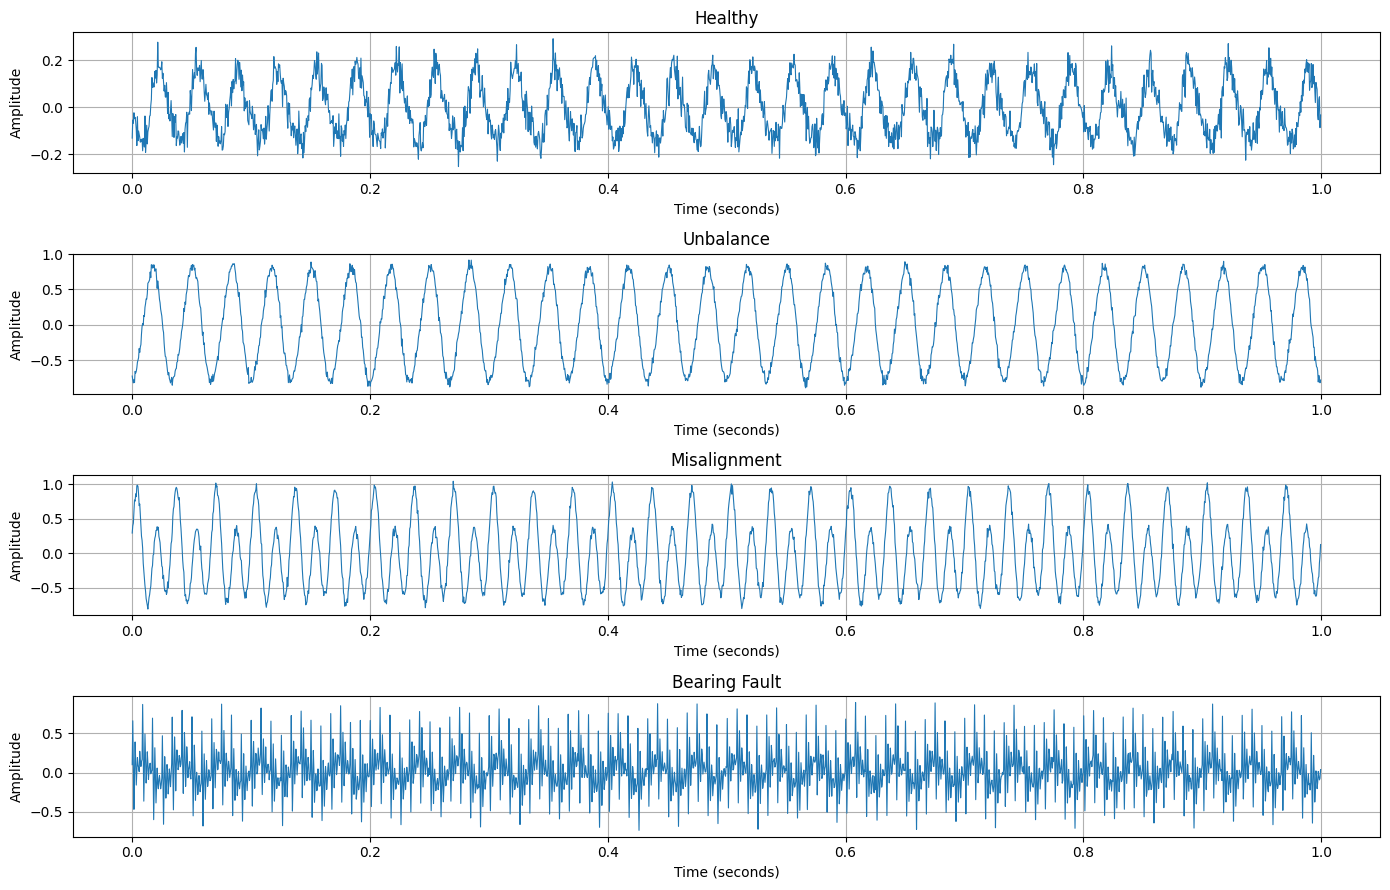

In [ ]:

plt.figure(figsize=(14, 9))

for i, fault in enumerate(fault_types):

    # Select one signal belonging to this condition
    idx = np.where(y_labels == fault)[0][0]

    plt.subplot(4, 1, i+1)

    plt.plot(t, X_signals[idx], linewidth=0.8)

    plt.title(fault)
    plt.ylabel("Amplitude")
    plt.xlabel("Time (seconds)")
    plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

from scipy.stats import skew, kurtosis

def extract_time_features(signal):

    features = {}

    # Basic statistical features
    features["mean"] = np.mean(signal)
    features["std"] = np.std(signal)
    features["variance"] = np.var(signal)

    # Amplitude-related features
    features["rms"] = np.sqrt(np.mean(signal**2))
    features["peak"] = np.max(np.abs(signal))
    features["peak_to_peak"] = np.ptp(signal)

    # Shape-related features
    features["skewness"] = skew(signal)
    features["kurtosis"] = kurtosis(signal)

    # Crest factor
    features["crest_factor"] = (
        features["peak"] / (features["rms"] + 1e-10)
    )

    # Energy
    features["energy"] = np.sum(signal**2)

    return features


In [ ]:
time_features = []

for signal in X_signals:

    features = extract_time_features(signal)

    time_features.append(features)

time_features_df = pd.DataFrame(time_features)

print("Feature extraction completed!")
print("Shape:", time_features_df.shape)

time_features_df.head()


Feature extraction completed!
Shape: (1000, 10)


,mean,std,variance,rms,peak,peak_to_peak,skewness,kurtosis,crest_factor,energy
0,-0.000315,0.116284,0.013522,0.116285,0.291078,0.543836,0.213284,-1.065989,2.503154,27.693258
1,-0.000732,0.115661,0.013377,0.115663,0.292256,0.535709,0.332793,-1.073980,2.526782,27.398137
2,-0.000761,0.114679,0.013151,0.114682,0.263468,0.513730,-0.140137,-1.058923,2.297379,26.935206
3,0.000021,0.114868,0.013195,0.114868,0.282337,0.498637,-0.332136,-1.094476,2.457925,27.022604
4,-0.000898,0.115667,0.013379,0.115671,0.275675,0.551208,-0.050575,-1.030955,2.383274,27.401742


<Figure size 900x500 with 0 Axes>

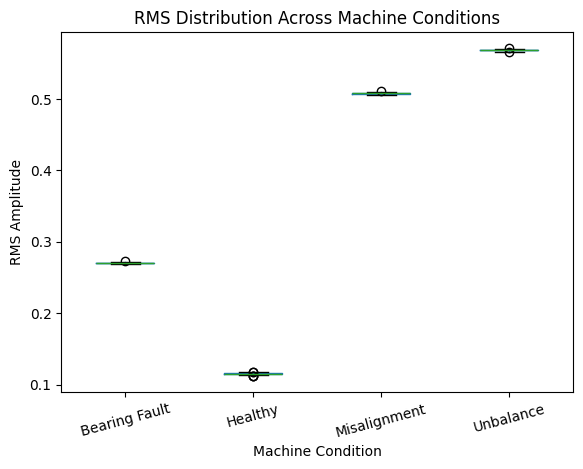

In [ ]:

time_features_df["fault_type"] = y_labels

plt.figure(figsize=(9, 5))

time_features_df.boxplot(
    column="rms",
    by="fault_type",
    grid=False
)

plt.title("RMS Distribution Across Machine Conditions")
plt.suptitle("")
plt.xlabel("Machine Condition")
plt.ylabel("RMS Amplitude")
plt.xticks(rotation=15)

plt.show()


In [ ]:

from scipy.fft import rfft, rfftfreq

def extract_frequency_features(signal):

    N = len(signal)

    # Remove DC component
    signal = signal - np.mean(signal)

    # FFT
    fft_values = np.abs(rfft(signal))

    frequencies = rfftfreq(N, d=1/fs)

    # Ignore zero frequency
    fft_values[0] = 0

    # Dominant frequency
    dominant_idx = np.argmax(fft_values)

    dominant_frequency = frequencies[dominant_idx]

    # Spectral centroid
    spectral_centroid = (
        np.sum(frequencies * fft_values)
        / (np.sum(fft_values) + 1e-10)
    )

    # Total spectral energy
    spectral_energy = np.sum(fft_values**2)

    # Frequency with maximum amplitude
    peak_amplitude = fft_values[dominant_idx]

    return {
        "dominant_frequency": dominant_frequency,
        "spectral_centroid": spectral_centroid,
        "spectral_energy": spectral_energy,
        "fft_peak_amplitude": peak_amplitude
    }


In [ ]:
frequency_features = []

for signal in X_signals:

    features = extract_frequency_features(signal)

    frequency_features.append(features)

frequency_features_df = pd.DataFrame(frequency_features)

print("Frequency feature extraction completed!")
print("Shape:", frequency_features_df.shape)

frequency_features_df.head()


Frequency feature extraction completed!
Shape: (1000, 4)


,dominant_frequency,spectral_centroid,spectral_energy,fft_peak_amplitude
0,30.0,470.800230,28357.837814,155.152102
1,30.0,466.664024,28055.357399,154.008085
2,30.0,457.136257,27581.692943,152.647299
3,30.0,464.956266,27674.921500,152.842367
4,30.0,472.631219,28057.784159,153.296176


In [ ]:
features_df = pd.concat(
    [time_features_df.drop(columns=["fault_type"]),
     frequency_features_df],
    axis=1
)

features_df["fault_type"] = y_labels

print("Final feature dataset shape:", features_df.shape)

features_df.head()


Final feature dataset shape: (1000, 15)


,mean,std,variance,rms,peak,peak_to_peak,skewness,kurtosis,crest_factor,energy,dominant_frequency,spectral_centroid,spectral_energy,fft_peak_amplitude,fault_type
0,-0.000315,0.116284,0.013522,0.116285,0.291078,0.543836,0.213284,-1.065989,2.503154,27.693258,30.0,470.800230,28357.837814,155.152102,Healthy
1,-0.000732,0.115661,0.013377,0.115663,0.292256,0.535709,0.332793,-1.073980,2.526782,27.398137,30.0,466.664024,28055.357399,154.008085,Healthy
2,-0.000761,0.114679,0.013151,0.114682,0.263468,0.513730,-0.140137,-1.058923,2.297379,26.935206,30.0,457.136257,27581.692943,152.647299,Healthy
3,0.000021,0.114868,0.013195,0.114868,0.282337,0.498637,-0.332136,-1.094476,2.457925,27.022604,30.0,464.956266,27674.921500,152.842367,Healthy
4,-0.000898,0.115667,0.013379,0.115671,0.275675,0.551208,-0.050575,-1.030955,2.383274,27.401742,30.0,472.631219,28057.784159,153.296176,Healthy


In [ ]:
X = features_df.drop(columns=["fault_type"])

y = features_df["fault_type"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Input shape: (1000, 14)
Target shape: (1000,)

Class distribution:
fault_type
Healthy          250
Unbalance        250
Misalignment     250
Bearing Fault    250
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 800
Testing samples: 200


In [ ]:
from xgboost import XGBClassifier

from sklearn.preprocessing import LabelEncoder

# Convert categorical labels into numerical labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Initialize XGBoost classifier
model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42
)

# Train the model
model.fit(X_train, y_train_encoded)

print("XGBoost training completed!")


XGBoost training completed!


In [ ]:
# Predict machine conditions
y_pred_encoded = model.predict(X_test)

# Convert numerical predictions back to labels
y_pred = label_encoder.inverse_transform(y_pred_encoded)

print("Actual labels:")
print(y_test.iloc[:10].values)

print("\nPredicted labels:")
print(y_pred[:10])


Actual labels:
['Misalignment' 'Healthy' 'Unbalance' 'Bearing Fault' 'Unbalance'
 'Misalignment' 'Unbalance' 'Healthy' 'Healthy' 'Bearing Fault']

Predicted labels:
['Misalignment' 'Healthy' 'Unbalance' 'Bearing Fault' 'Unbalance'
 'Misalignment' 'Unbalance' 'Healthy' 'Healthy' 'Bearing Fault']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=label_encoder.classes_,
        zero_division=0
    )
)


Model Accuracy: 100.0 %

Classification Report:
               precision    recall  f1-score   support

Bearing Fault       1.00      1.00      1.00        50
      Healthy       1.00      1.00      1.00        50
 Misalignment       1.00      1.00      1.00        50
    Unbalance       1.00      1.00      1.00        50

     accuracy                           1.00       200
    macro avg       1.00      1.00      1.00       200
 weighted avg       1.00      1.00      1.00       200



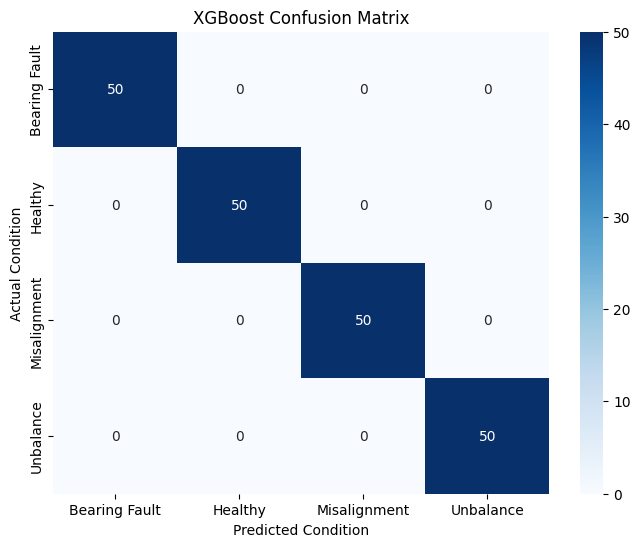

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=label_encoder.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Condition")
plt.ylabel("Actual Condition")
plt.title("XGBoost Confusion Matrix")

plt.show()


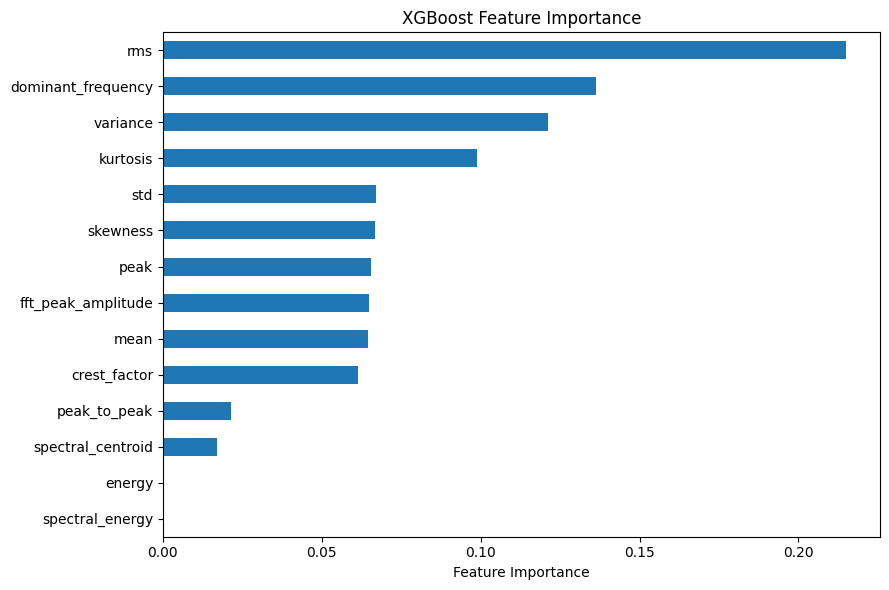

In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 6))

importance.plot(kind="barh")

plt.xlabel("Feature Importance")
plt.title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()


In [ ]:
import joblib

joblib.dump(model, "xgboost_fault_classifier.pkl")

joblib.dump(label_encoder, "label_encoder.pkl")

print("Model and label encoder saved successfully!")


Model and label encoder saved successfully!


In [ ]:

def generate_vibration_with_severity(fault_type, severity):

    noise = np.random.normal(0, 0.04, len(t))
    phase = np.random.uniform(0, 2*np.pi)

    # Severity-dependent amplitude scaling
    scale = severity / 3 if severity > 0 else 0

    if fault_type == "Healthy":

        signal = (
            0.15 * np.sin(2*np.pi*rot_freq*t + phase)
            + 0.03 * np.sin(4*np.pi*rot_freq*t)
            + noise
        )

    elif fault_type == "Unbalance":

        signal = (
            (0.2 + 0.8*scale)
            * np.sin(2*np.pi*rot_freq*t + phase)
            + 0.05 * np.sin(4*np.pi*rot_freq*t)
            + noise
        )

    elif fault_type == "Misalignment":

        signal = (
            0.3 * np.sin(2*np.pi*rot_freq*t + phase)
            + (0.2 + 0.65*scale)
            * np.sin(4*np.pi*rot_freq*t)
            + noise
        )

    elif fault_type == "Bearing Fault":

        signal = (
            0.15 * np.sin(2*np.pi*rot_freq*t)
            + noise
        )

        impact_freq = 120
        resonance_freq = 500

        for impact_time in np.arange(0, duration, 1/impact_freq):

            idx = int(impact_time * fs)

            decay_length = min(
                int(0.015 * fs),
                len(t) - idx
            )

            local_t = np.arange(decay_length) / fs

            impact = (
                0.8 * scale
                * np.exp(-local_t / 0.003)
                * np.sin(2*np.pi*resonance_freq*local_t)
            )

            signal[idx:idx+decay_length] += impact

    return signal


In [ ]:

fault_types = [
    "Healthy",
    "Unbalance",
    "Misalignment",
    "Bearing Fault"
]

X_severity = []
y_fault = []
y_severity = []

samples_per_level = 250

for fault in fault_types:

    if fault == "Healthy":
        severity_levels = [0]
    else:
        severity_levels = [1, 2, 3]

    for severity in severity_levels:

        for _ in range(samples_per_level):

            signal = generate_vibration_with_severity(
                fault, severity
            )

            X_severity.append(signal)
            y_fault.append(fault)
            y_severity.append(severity)


X_severity = np.array(X_severity)
y_fault = np.array(y_fault)
y_severity = np.array(y_severity)

print("New dataset:", X_severity.shape)
print("Fault labels:", y_fault.shape)
print("Severity labels:", y_severity.shape)


New dataset: (2500, 2048)
Fault labels: (2500,)
Severity labels: (2500,)


In [ ]:

severity_time_features = pd.DataFrame([
    extract_time_features(signal)
    for signal in X_severity
])

severity_frequency_features = pd.DataFrame([
    extract_frequency_features(signal)
    for signal in X_severity
])

severity_features = pd.concat(
    [severity_time_features, severity_frequency_features],
    axis=1
)

severity_features["fault_type"] = y_fault
severity_features["severity"] = y_severity

severity_features.head()


,mean,std,variance,rms,peak,peak_to_peak,skewness,kurtosis,crest_factor,energy,dominant_frequency,spectral_centroid,spectral_energy,fft_peak_amplitude,fault_type,severity
0,0.000063,0.115032,0.013232,0.115032,0.274785,0.534926,-0.148424,-1.071337,2.388771,27.099794,30.0,462.012336,27754.165580,153.154112,Healthy,0
1,-0.000573,0.115209,0.013273,0.115210,0.255658,0.498314,0.231654,-1.089093,2.219064,27.183828,30.0,470.061908,27835.903194,154.251146,Healthy,0
2,-0.001017,0.117636,0.013838,0.117640,0.288937,0.533849,0.332080,-1.082173,2.456107,28.342673,30.0,463.134966,29022.717379,156.847738,Healthy,0
3,-0.001135,0.113963,0.012988,0.113968,0.284762,0.521796,0.359684,-1.012534,2.498604,26.601049,30.0,460.440345,27237.022820,151.531994,Healthy,0
4,-0.000298,0.116291,0.013524,0.116291,0.331488,0.558185,0.303201,-1.023560,2.850493,27.696529,30.0,459.266293,28361.584637,154.856670,Healthy,0


In [ ]:

from xgboost import XGBRegressor

X_reg = severity_features.drop(
    columns=["fault_type", "severity"]
)

y_reg = severity_features["severity"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = (
    train_test_split(
        X_reg,
        y_reg,
        test_size=0.2,
        random_state=42
    )
)

severity_model = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

severity_model.fit(X_train_reg, y_train_reg)

print("Severity regression model trained!")


Severity regression model trained!


In [ ]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

severity_predictions = severity_model.predict(X_test_reg)

mae = mean_absolute_error(
    y_test_reg, severity_predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test_reg, severity_predictions)
)

r2 = r2_score(
    y_test_reg, severity_predictions
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 0.0008106118766590953
RMSE: 0.00396107453449788
R2 Score: 0.9999831318855286


In [ ]:

def predict_machine_health(signal):

    # Extract time-domain features
    time_features = extract_time_features(signal)

    # Extract frequency-domain features
    freq_features = extract_frequency_features(signal)

    # Combine features
    features = {**time_features, **freq_features}

    # Convert into DataFrame
    input_df = pd.DataFrame([features])

    # Predict fault type
    fault_encoded = model.predict(input_df)[0]

    fault_type = label_encoder.inverse_transform(
        [fault_encoded]
    )[0]

    # Predict severity
    severity = severity_model.predict(input_df)[0]

    severity = np.clip(np.rint(severity), 0, 3)

    # Machine health status
    if fault_type == "Healthy":
        health_status = "Healthy"
        severity = 0

    elif severity == 1:
        health_status = "Mild Fault"

    elif severity == 2:
        health_status = "Moderate Fault"

    else:
        health_status = "Severe Fault"

    return {
        "Fault Type": fault_type,
        "Severity": int(severity),
        "Machine Status": health_status
    }


In [ ]:

# Select one signal
test_signal = X_severity[500]

# Predict machine health
result = predict_machine_health(test_signal)

print("Machine Health Prediction")
print("-------------------------")

for key, value in result.items():
    print(key, ":", value)


Machine Health Prediction
-------------------------
Fault Type : Unbalance
Severity : 2
Machine Status : Moderate Fault


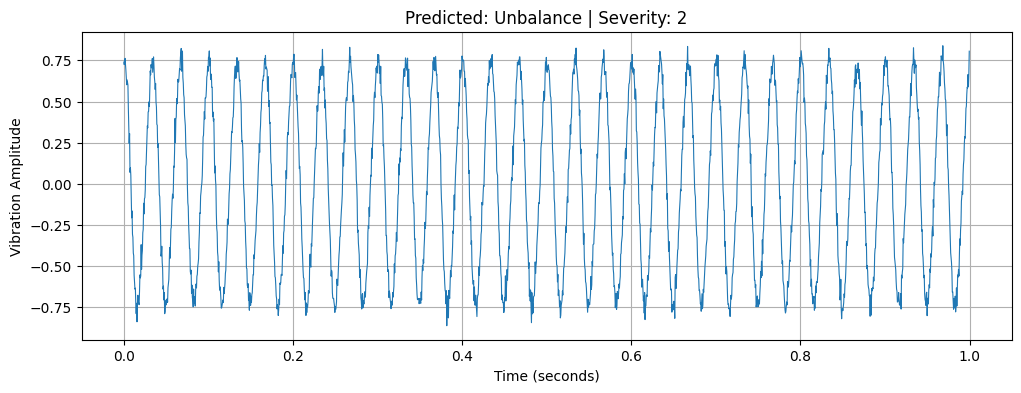

In [ ]:

plt.figure(figsize=(12, 4))

plt.plot(t, test_signal, linewidth=0.8)

plt.title(
    f"Predicted: {result['Fault Type']} | "
    f"Severity: {result['Severity']}"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Vibration Amplitude")
plt.grid(True)

plt.show()


In [ ]:

# Save XGBoost models in native JSON format

model.save_model("fault_classifier.json")

severity_model.save_model("severity_regressor.json")

# Save label encoder separately
import joblib

joblib.dump(label_encoder, "label_encoder.pkl")

print("Models exported successfully!")

Models exported successfully!


In [ ]:
from google.colab import files

files.download("fault_classifier.json")
files.download("severity_regressor.json")
files.download("label_encoder.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
from google.colab import files

# Select a synthetic vibration signal
test_signal = X_severity[500]

# Export it to CSV
pd.DataFrame({
    "vibration_amplitude": test_signal
}).to_csv("test_vibration.csv", index=False)

files.download("test_vibration.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Training using MATLAB Simulation Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBClassifier, XGBRegressor

import joblib
import json
import os

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("rotor_fault_realistic.csv")

print("Dataset shape:", df.shape)
display(df.head())

Saving rotor_fault_realistic.csv to rotor_fault_realistic.csv
Dataset shape: (600, 31)


,RPM,Condition,Severity,Replicate,BPFO_Hz,RMS_m_s2,Std_m_s2,Peak_m_s2,Kurtosis,CrestFactor,...,SensorMountingGain,TransientEvent,Run_ID,OperatingPoint_ID,RMS_Y_m_s2,Peak_Y_m_s2,Kurtosis_Y,Amp1X_Y_m_s2,Amp2X_Y_m_s2,AmpBPFO_Y_m_s2
0,1200,healthy,0,1,63.848288,0.004325,0.004325,0.00917,1.881528,2.120301,...,0.940558,0,1,1,0.003454,0.00794,1.843467,0.000129,0.000045,0.000028
1,1200,healthy,0,2,63.804203,0.002277,0.002277,0.00815,2.710429,3.579259,...,0.912800,0,2,1,0.001974,0.00769,2.679962,0.000132,0.000093,0.000115
2,1200,healthy,0,3,64.072520,0.001750,0.001749,0.00507,2.272509,2.897102,...,1.016841,0,3,1,0.001335,0.00398,2.421326,0.000105,0.000016,0.000033
3,1200,healthy,0,4,63.860736,0.005948,0.005948,0.01500,1.828571,2.521891,...,1.082336,0,4,1,0.004917,0.01346,1.947677,0.000152,0.000119,0.000141
4,1200,healthy,0,5,64.049876,0.002777,0.002777,0.00685,1.800897,2.466490,...,0.912404,0,5,1,0.002253,0.00561,1.834643,0.000090,0.000036,0.000044


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFault distribution:")
print(df["Condition"].value_counts())

print("\nSeverity distribution:")
print(df["Severity"].value_counts())

print("\nRPM distribution:")
print(df["RPM"].value_counts())

Columns:
['RPM', 'Condition', 'Severity', 'Replicate', 'BPFO_Hz', 'RMS_m_s2', 'Std_m_s2', 'Peak_m_s2', 'Kurtosis', 'CrestFactor', 'Amp1X_m_s2', 'Amp2X_m_s2', 'AmpBPFO_m_s2', 'RPM_ActualMean', 'RPM_ActualStd', 'NominalLoad_Percent', 'MeanLoad_Percent', 'Temperature_C', 'AmbientTemperature_C', 'SensorNoiseStd_m_s2', 'SensorBandwidth_Hz', 'SensorMountingGain', 'TransientEvent', 'Run_ID', 'OperatingPoint_ID', 'RMS_Y_m_s2', 'Peak_Y_m_s2', 'Kurtosis_Y', 'Amp1X_Y_m_s2', 'Amp2X_Y_m_s2', 'AmpBPFO_Y_m_s2']

Missing values:
0

Fault distribution:
Condition
unbalance        180
misalignment     180
bearing_outer    180
healthy           60
Name: count, dtype: int64

Severity distribution:
Severity
1    180
2    180
3    180
0     60
Name: count, dtype: int64

RPM distribution:
RPM
1200    200
1800    200
2400    200
Name: count, dtype: int64


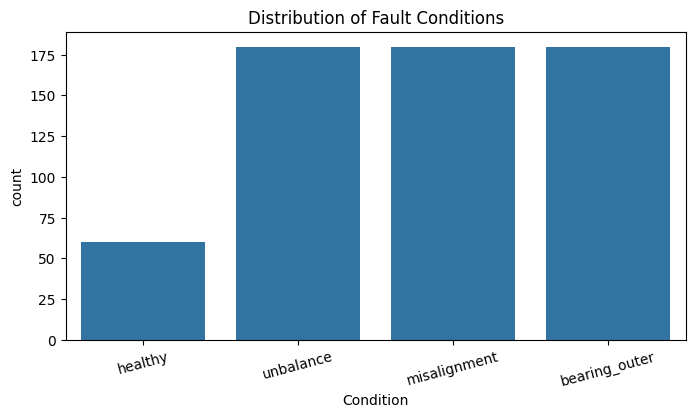

In [4]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Condition")
plt.title("Distribution of Fault Conditions")
plt.xticks(rotation=15)
plt.show()

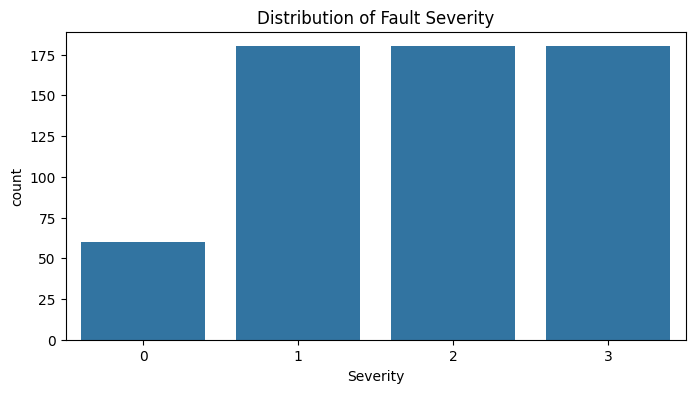

In [5]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Severity")
plt.title("Distribution of Fault Severity")
plt.show()

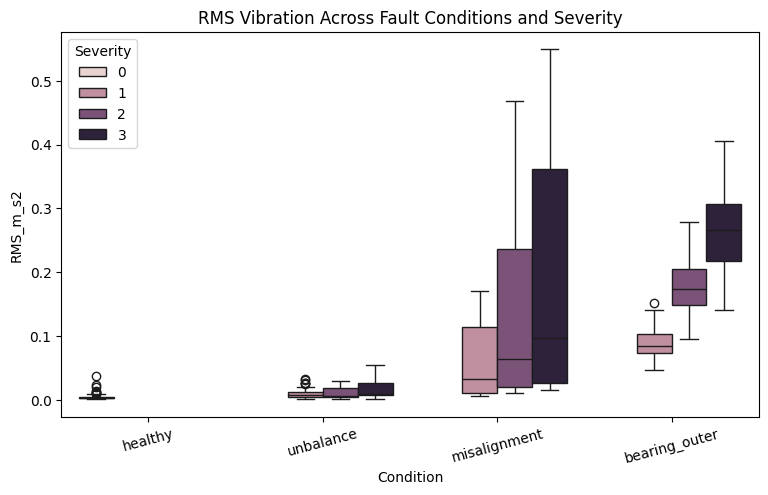

In [6]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Condition",
    y="RMS_m_s2",
    hue="Severity"
)

plt.title("RMS Vibration Across Fault Conditions and Severity")
plt.xticks(rotation=15)
plt.show()

In [7]:
feature_columns = [
    "RPM",
    "NominalLoad_Percent",

    "RMS_m_s2",
    "Std_m_s2",
    "Peak_m_s2",
    "Kurtosis",
    "CrestFactor",

    "Amp1X_m_s2",
    "Amp2X_m_s2",
    "AmpBPFO_m_s2",

    "RMS_Y_m_s2",
    "Peak_Y_m_s2",
    "Kurtosis_Y",

    "Amp1X_Y_m_s2",
    "Amp2X_Y_m_s2",
    "AmpBPFO_Y_m_s2"
]

X = df[feature_columns].copy()

# Target for fault classification
y_fault = df["Condition"].copy()

# Target for severity estimation
y_severity = df["Severity"].copy()

# Group information used for splitting
groups = df["OperatingPoint_ID"]

In [8]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y_fault, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_fault_train = y_fault.iloc[train_idx]
y_fault_test = y_fault.iloc[test_idx]

y_severity_train = y_severity.iloc[train_idx]
y_severity_test = y_severity.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training operating points:",
      sorted(groups.iloc[train_idx].unique()))

print("Testing operating points:",
      sorted(groups.iloc[test_idx].unique()))

Training samples: 450
Testing samples: 150
Training operating points: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(12)]
Testing operating points: [np.int64(1), np.int64(10), np.int64(11)]


In [9]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_fault_train)
y_test_encoded = label_encoder.transform(y_fault_test)

print("Class mapping:")

for i, label in enumerate(label_encoder.classes_):
    print(i, ":", label)

Class mapping:
0 : bearing_outer
1 : healthy
2 : misalignment
3 : unbalance


In [10]:
fault_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42
)

fault_model.fit(X_train, y_train_encoded)

print("Fault classification model trained!")

Fault classification model trained!


In [11]:
y_pred_encoded = fault_model.predict(X_test)

y_pred = label_encoder.inverse_transform(y_pred_encoded)
y_actual = label_encoder.inverse_transform(y_test_encoded)

accuracy = accuracy_score(y_actual, y_pred)

print("Fault Classification Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_actual, y_pred))

Fault Classification Accuracy: 0.9533333333333334

Classification Report:
               precision    recall  f1-score   support

bearing_outer       1.00      1.00      1.00        45
      healthy       1.00      0.93      0.97        15
 misalignment       0.88      0.98      0.93        45
    unbalance       0.98      0.89      0.93        45

     accuracy                           0.95       150
    macro avg       0.96      0.95      0.96       150
 weighted avg       0.96      0.95      0.95       150



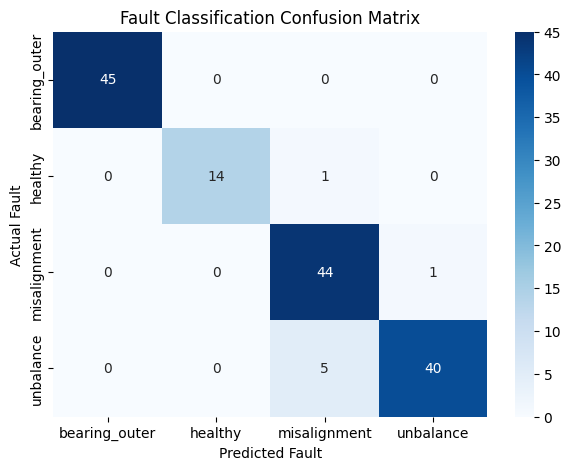

In [12]:
cm = confusion_matrix(
    y_actual,
    y_pred,
    labels=label_encoder.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Fault")
plt.ylabel("Actual Fault")
plt.title("Fault Classification Confusion Matrix")
plt.show()

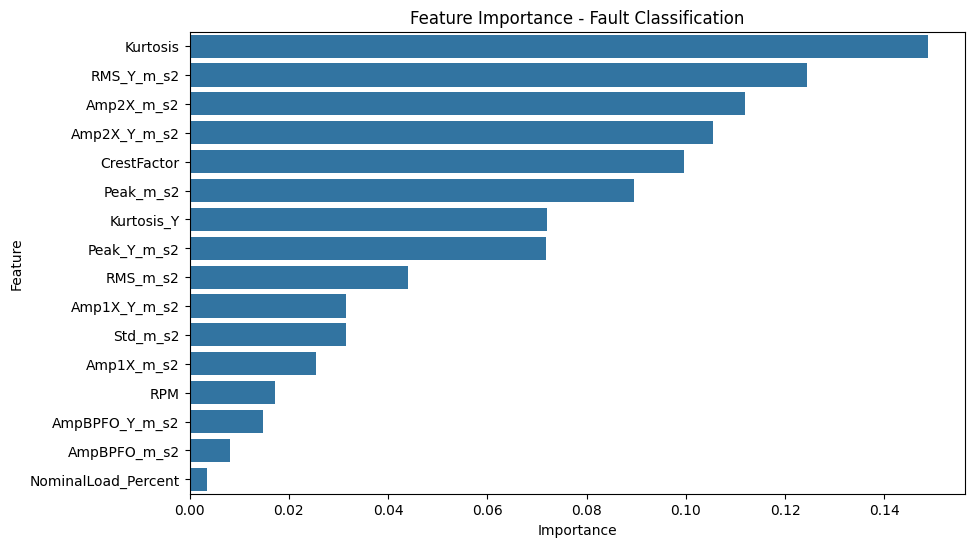

,Feature,Importance
5,Kurtosis,0.148727
10,RMS_Y_m_s2,0.124418
8,Amp2X_m_s2,0.112026
14,Amp2X_Y_m_s2,0.105475
6,CrestFactor,0.099577
4,Peak_m_s2,0.089617
12,Kurtosis_Y,0.072086
11,Peak_Y_m_s2,0.071732
2,RMS_m_s2,0.044091
13,Amp1X_Y_m_s2,0.031478


In [13]:
importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": fault_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Fault Classification")
plt.show()

display(importance)

In [14]:
faulty_mask_train = y_fault_train != "healthy"
faulty_mask_test = y_fault_test != "healthy"

X_severity_train = X_train.loc[faulty_mask_train].copy()
X_severity_test = X_test.loc[faulty_mask_test].copy()

y_severity_train_faulty = y_severity_train.loc[faulty_mask_train]
y_severity_test_faulty = y_severity_test.loc[faulty_mask_test]

# Add fault type as an input feature
X_severity_train["Condition"] = y_fault_train.loc[faulty_mask_train]
X_severity_test["Condition"] = y_fault_test.loc[faulty_mask_test]

# One-hot encode fault type
X_severity_train = pd.get_dummies(
    X_severity_train,
    columns=["Condition"],
    dtype=int
)

X_severity_test = pd.get_dummies(
    X_severity_test,
    columns=["Condition"],
    dtype=int
)

# Ensure identical columns and order
X_severity_test = X_severity_test.reindex(
    columns=X_severity_train.columns,
    fill_value=0
)

print("Severity training samples:", len(X_severity_train))
print("Severity testing samples:", len(X_severity_test))

Severity training samples: 405
Severity testing samples: 135


In [15]:
severity_model = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

severity_model.fit(
    X_severity_train,
    y_severity_train_faulty
)

print("Severity model trained!")

Severity model trained!


In [16]:
severity_predictions = severity_model.predict(X_severity_test)

# Severity is restricted to levels 1, 2 and 3
severity_predictions_rounded = np.clip(
    np.rint(severity_predictions),
    1,
    3
).astype(int)

mae = mean_absolute_error(
    y_severity_test_faulty,
    severity_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_severity_test_faulty,
        severity_predictions
    )
)

r2 = r2_score(
    y_severity_test_faulty,
    severity_predictions
)

print("Severity Estimation Results")
print("---------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

print("\nRounded Severity Classification Report:")
print(classification_report(
    y_severity_test_faulty,
    severity_predictions_rounded
))

Severity Estimation Results
---------------------------
MAE: 0.2231617271900177
RMSE: 0.30450843782353626
R2 Score: 0.8609119057655334

Rounded Severity Classification Report:
              precision    recall  f1-score   support

           1       0.93      0.96      0.95        45
           2       0.82      0.91      0.86        45
           3       0.97      0.84      0.90        45

    accuracy                           0.90       135
   macro avg       0.91      0.90      0.90       135
weighted avg       0.91      0.90      0.90       135



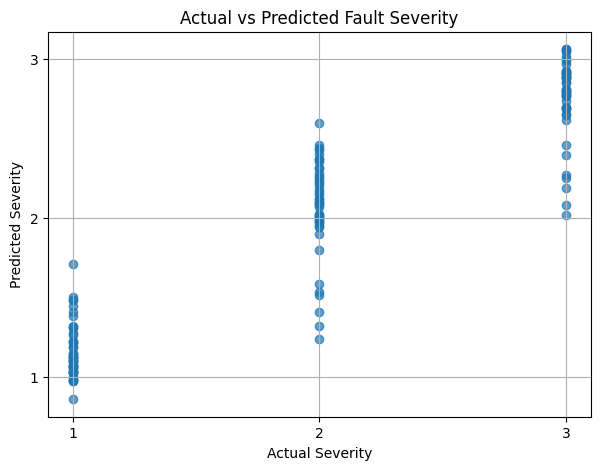

In [17]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_severity_test_faulty,
    severity_predictions,
    alpha=0.7
)

plt.xlabel("Actual Severity")
plt.ylabel("Predicted Severity")
plt.title("Actual vs Predicted Fault Severity")

plt.xticks([1, 2, 3])
plt.yticks([1, 2, 3])

plt.grid(True)
plt.show()

In [18]:
def predict_machine_health(input_data):

    # Convert input to DataFrame
    input_df = pd.DataFrame([input_data])

    # Ensure correct feature order
    input_df = input_df[feature_columns]

    # Predict fault
    fault_encoded = fault_model.predict(input_df)[0]

    fault_type = label_encoder.inverse_transform(
        [fault_encoded]
    )[0]

    probabilities = fault_model.predict_proba(input_df)[0]

    confidence = float(np.max(probabilities)) * 100

    # Healthy machine
    if fault_type == "healthy":

        severity = 0
        status = "Healthy"

    else:

        severity_input = input_df.copy()
        severity_input["Condition"] = fault_type

        severity_input = pd.get_dummies(
            severity_input,
            columns=["Condition"],
            dtype=int
        )

        severity_input = severity_input.reindex(
            columns=X_severity_train.columns,
            fill_value=0
        )

        predicted_severity = severity_model.predict(
            severity_input
        )[0]

        severity = int(np.clip(
            np.rint(predicted_severity),
            1,
            3
        ))

        if severity == 1:
            status = "Mild Fault"
        elif severity == 2:
            status = "Moderate Fault"
        else:
            status = "Severe Fault"

    return {
        "Fault Type": fault_type,
        "Severity": severity,
        "Machine Status": status,
        "Fault Classification Confidence": round(confidence, 2)
    }

In [19]:
sample = X_test.iloc[0].to_dict()

result = predict_machine_health(sample)

print(result)

print("\nActual fault:", y_fault_test.iloc[0])
print("Actual severity:", y_severity_test.iloc[0])

{'Fault Type': 'healthy', 'Severity': 0, 'Machine Status': 'Healthy', 'Fault Classification Confidence': 97.98}

Actual fault: healthy
Actual severity: 0


In [20]:
os.makedirs("models", exist_ok=True)

fault_model.save_model("models/fault_classifier.json")

severity_model.save_model("models/severity_regressor.json")

joblib.dump(
    label_encoder,
    "models/label_encoder.pkl"
)

with open("models/feature_columns.json", "w") as f:
    json.dump(feature_columns, f)

with open("models/severity_feature_columns.json", "w") as f:
    json.dump(list(X_severity_train.columns), f)

print("All models and feature configurations saved!")

All models and feature configurations saved!


In [21]:
!zip -r final_models.zip models

files.download("final_models.zip")

  adding: models/ (stored 0%)
  adding: models/label_encoder.pkl (deflated 35%)
  adding: models/severity_regressor.json (deflated 78%)
  adding: models/severity_feature_columns.json (deflated 50%)
  adding: models/fault_classifier.json (deflated 84%)
  adding: models/feature_columns.json (deflated 51%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
print("TRAINING DISTRIBUTION")
print(pd.DataFrame({
    "Condition": y_fault_train,
    "Severity": y_severity_train
}).groupby(["Condition", "Severity"]).size())

print("\nTESTING DISTRIBUTION")
print(pd.DataFrame({
    "Condition": y_fault_test,
    "Severity": y_severity_test
}).groupby(["Condition", "Severity"]).size())

TRAINING DISTRIBUTION
Condition      Severity
bearing_outer  1           45
               2           45
               3           45
healthy        0           45
misalignment   1           45
               2           45
               3           45
unbalance      1           45
               2           45
               3           45
dtype: int64

TESTING DISTRIBUTION
Condition      Severity
bearing_outer  1           15
               2           15
               3           15
healthy        0           15
misalignment   1           15
               2           15
               3           15
unbalance      1           15
               2           15
               3           15
dtype: int64
